<a href="https://colab.research.google.com/github/ToyKungTM/Character_Image_Classification/blob/main/Character_Image_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ช่องที่ 1: เชื่อมต่อ Drive และตั้งค่า

In [ ]:
from google.colab import drive, files
drive.mount('/content/drive')

import copy
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

Mounted at /content/drive


In [ ]:
# แก้ path นี้ให้ตรงกับโฟลเดอร์รูปของคุณ
DATA_DIR = '/content/drive/MyDrive/<ชื่อโฟลเดอร์รูป>'

IMG_SIZE = 224
BATCH_SIZE = 32
MAX_EPOCHS = 25
LR = 1e-4
SEED = 42
ES_PATIENCE = 5      # หยุดเทรนถ้า val loss ไม่ดีขึ้นกี่รอบ
LR_PATIENCE = 3      # ลด learning rate ถ้า val loss ไม่ดีขึ้นกี่รอบ
MODEL_PATH = '/content/zzz_alexnet.pth'

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('ใช้อุปกรณ์:', device)

ใช้อุปกรณ์: cpu


ช่องที่ 2: โหลดรูปและแบ่งข้อมูล 70/15/15

In [ ]:
def load_rgb(path):
    img = Image.open(path)
    if img.mode in ('RGBA', 'LA', 'P'):
        img = img.convert('RGBA')
        bg = Image.new('RGBA', img.size, (255, 255, 255, 255))
        bg.alpha_composite(img)
        img = bg
    return img.convert('RGB')

# ใช้ ImageFolder เพื่ออ่านชื่อโฟลเดอร์เป็น Label
base = datasets.ImageFolder(DATA_DIR)
class_names = base.classes
paths = [p for p, _ in base.samples]
labels = [l for _, l in base.samples]
print('ตัวละคร:', class_names)
print('รูปทั้งหมด:', len(paths))

# แบ่งรอบแรก: ฝึก 70% / ที่เหลือ 30%
idx = np.arange(len(paths))
train_idx, temp_idx = train_test_split(
    idx, test_size=0.30, stratify=labels, random_state=SEED)

# แบ่งรอบสอง: ที่เหลือ 30% แบ่งครึ่งเป็นตรวจสอบ 15% / ทดสอบ 15%
temp_labels = [labels[i] for i in temp_idx]
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, stratify=temp_labels, random_state=SEED)

print('ฝึก:', len(train_idx), '| ตรวจสอบ:', len(val_idx), '| ทดสอบ:', len(test_idx))

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# Augmentation ใช้เฉพาะชุดฝึก (ไม่เปลี่ยนเฉดสี)
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

class ImgDataset(Dataset):
    def __init__(self, idx_list, tf):
        self.paths = [paths[i] for i in idx_list]
        self.labels = [labels[i] for i in idx_list]
        self.tf = tf

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        return self.tf(load_rgb(self.paths[i])), self.labels[i]

train_loader = DataLoader(ImgDataset(train_idx, train_tf), batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(ImgDataset(val_idx, eval_tf), batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(ImgDataset(test_idx, eval_tf), batch_size=BATCH_SIZE,
                         shuffle=False, num_workers=2, pin_memory=True)

ตัวละคร: ['Bella', 'Burnice', 'Ellen', 'Grace', 'JaneDoe', 'King Caesar', 'Miyabi', 'Nicole', 'Wise', 'Yanagi']
รูปทั้งหมด: 1000
ฝึก: 700 | ตรวจสอบ: 150 | ทดสอบ: 150


ช่องที่ 3: สร้างโมเดล AlexNet

In [ ]:
model = models.alexnet(weights=models.AlexNet_Weights.IMAGENET1K_V1)
model.classifier[6] = nn.Linear(4096, len(class_names))
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=LR_PATIENCE)

ช่องที่ 4: เทรนพร้อม Early Stopping และลด learning rate

In [ ]:
def run_epoch(loader, train):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_loss = float('inf')
best_weights = None
best_epoch = 0
wait = 0

for epoch in range(1, MAX_EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, True)
    va_loss, va_acc = run_epoch(val_loader, False)
    scheduler.step(va_loss)

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(va_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(va_acc)

    lr_now = optimizer.param_groups[0]['lr']
    print(f'รอบ {epoch:02d} | train loss {tr_loss:.4f} acc {tr_acc:.3f} | '
          f'val loss {va_loss:.4f} acc {va_acc:.3f} | lr {lr_now:.6f}')

    if va_loss < best_loss:
        best_loss = va_loss
        best_weights = copy.deepcopy(model.state_dict())
        best_epoch = epoch
        wait = 0
    else:
        wait += 1
        if wait >= ES_PATIENCE:
            print(f'หยุดเทรนที่รอบ {epoch} (val loss ไม่ดีขึ้น {ES_PATIENCE} รอบติด)')
            break

model.load_state_dict(best_weights)
print('ใช้น้ำหนักจากรอบที่ดีที่สุด: รอบ', best_epoch)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


รอบ 01 | train loss 1.6924 acc 0.429 | val loss 0.8338 acc 0.720 | lr 0.000100
รอบ 02 | train loss 0.6688 acc 0.793 | val loss 0.4332 acc 0.847 | lr 0.000100
รอบ 03 | train loss 0.3397 acc 0.894 | val loss 0.4391 acc 0.847 | lr 0.000100
รอบ 04 | train loss 0.2741 acc 0.889 | val loss 0.2741 acc 0.913 | lr 0.000100
รอบ 05 | train loss 0.1681 acc 0.941 | val loss 0.2344 acc 0.913 | lr 0.000100
รอบ 06 | train loss 0.1061 acc 0.960 | val loss 0.2388 acc 0.920 | lr 0.000100
รอบ 07 | train loss 0.0783 acc 0.980 | val loss 0.2371 acc 0.933 | lr 0.000100
รอบ 08 | train loss 0.0776 acc 0.976 | val loss 0.2533 acc 0.933 | lr 0.000100
รอบ 09 | train loss 0.0592 acc 0.983 | val loss 0.2444 acc 0.913 | lr 0.000050
รอบ 10 | train loss 0.0569 acc 0.977 | val loss 0.2096 acc 0.953 | lr 0.000050
รอบ 11 | train loss 0.0226 acc 0.997 | val loss 0.1615 acc 0.960 | lr 0.000050
รอบ 12 | train loss 0.0226 acc 0.994 | val loss 0.1816 acc 0.967 | lr 0.000050
รอบ 13 | train loss 0.0172 acc 0.997 | val loss 0.18

ช่องที่ 5: กราฟการเทรน

/tmp/ipykernel_1846/1578024129.py:18: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1846/1578024129.py:18: UserWarning: Glyph 3629 (\N{THAI CHARACTER O ANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1846/1578024129.py:18: UserWarning: Glyph 3610 (\N{THAI CHARACTER BO BAIMAI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1846/1578024129.py:18: UserWarning: Glyph 3607 (\N{THAI CHARACTER THO THAHAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1846/1578024129.py:18: UserWarning: Glyph 3637 (\N{THAI CHARACTER SARA II}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1846/1578024129.py:18: UserWarning: Glyph 3656 (\N{THAI CHARACTER MAI EK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1846/1578024129.py:18: UserWarning: Glyph 3604 (\N{THAI CHARACTER DO DEK}) missing from font(s) DejaVu Sans.

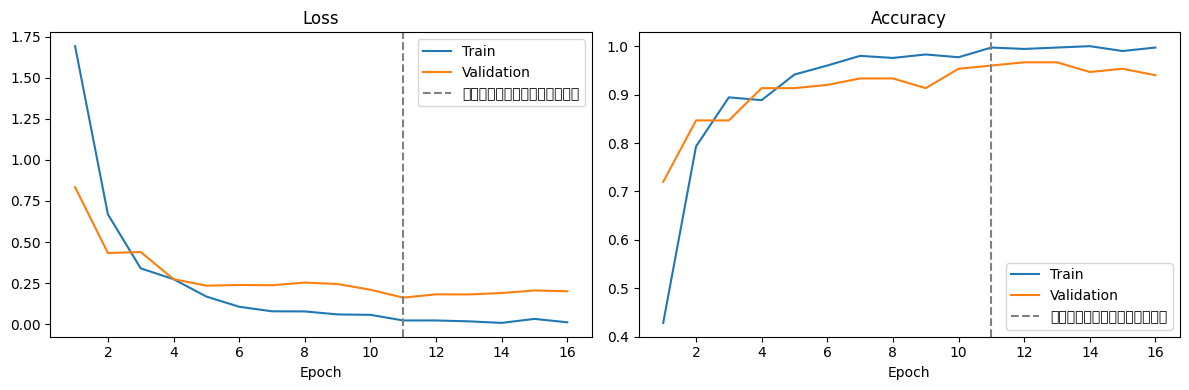

In [ ]:
epochs = range(1, len(history['train_loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(epochs, history['train_loss'], label='Train')
ax[0].plot(epochs, history['val_loss'], label='Validation')
ax[0].axvline(best_epoch, color='gray', linestyle='--', label='รอบที่ดีที่สุด')
ax[0].set_title('Loss')
ax[0].set_xlabel('Epoch')
ax[0].legend()

ax[1].plot(epochs, history['train_acc'], label='Train')
ax[1].plot(epochs, history['val_acc'], label='Validation')
ax[1].axvline(best_epoch, color='gray', linestyle='--', label='Best epoch')
ax[1].set_title('Accuracy')
ax[1].set_xlabel('Epoch')
ax[1].legend()

plt.tight_layout()
plt.show()

ช่องที่ 6: วัดผลด้วยชุดทดสอบ

Accuracy: 0.9533
Precision (macro): 0.9544
Recall (macro): 0.9533
F1 (macro): 0.9533

              precision    recall  f1-score   support

       Bella      1.000     1.000     1.000        15
     Burnice      0.929     0.867     0.897        15
       Ellen      0.933     0.933     0.933        15
       Grace      1.000     1.000     1.000        15
     JaneDoe      0.933     0.933     0.933        15
 King Caesar      0.882     1.000     0.938        15
      Miyabi      1.000     1.000     1.000        15
      Nicole      0.933     0.933     0.933        15
        Wise      0.933     0.933     0.933        15
      Yanagi      1.000     0.933     0.966        15

    accuracy                          0.953       150
   macro avg      0.954     0.953     0.953       150
weighted avg      0.954     0.953     0.953       150



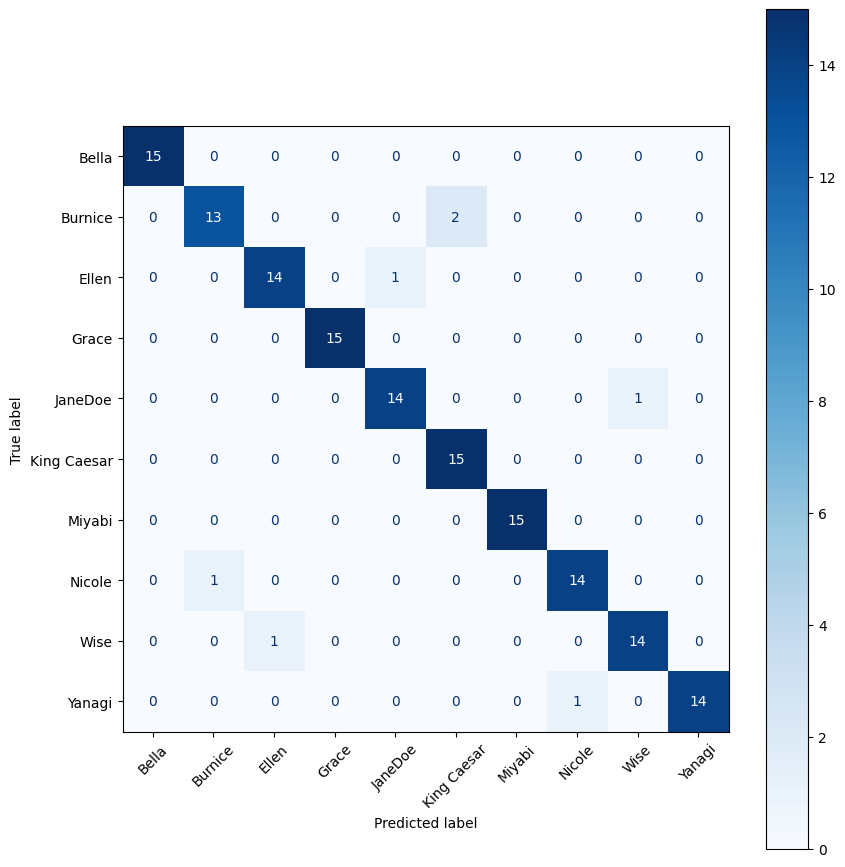

In [ ]:
model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for x, y in test_loader:
        out = model(x.to(device))
        y_pred += out.argmax(1).cpu().tolist()
        y_true += y.tolist()

acc = accuracy_score(y_true, y_pred)
p, r, f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average='macro', zero_division=0)

print(f'Accuracy: {acc:.4f}')
print(f'Precision (macro): {p:.4f}')
print(f'Recall (macro): {r:.4f}')
print(f'F1 (macro): {f1:.4f}')
print()
print(classification_report(y_true, y_pred, target_names=class_names,
                            digits=3, zero_division=0))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(9, 9))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, xticks_rotation=45, cmap='Blues')
plt.tight_layout()
plt.show()

ช่องที่ 7: บันทึกโมเดลลงใน Colab

In [ ]:
torch.save({'state_dict': model.state_dict(), 'class_names': class_names}, MODEL_PATH)
print('บันทึกแล้วที่', MODEL_PATH)

บันทึกแล้วที่ /content/zzz_alexnet.pth


ช่องที่ 8: ส่วนใช้งาน อัปโหลดรูปแล้วให้โมเดลทาย

In [ ]:
import os
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt
from google.colab import files

MODEL_PATH = '/content/zzz_alexnet.pth'
IMG_SIZE = 224
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ถ้าไม่พบไฟล์โมเดลใน Colab ให้อัปโหลดไฟล์ .pth ที่ดาวน์โหลดเก็บไว้
if not os.path.exists(MODEL_PATH):
    print('ไม่พบไฟล์โมเดล กรุณาอัปโหลดไฟล์ zzz_alexnet.pth')
    up = files.upload()
    MODEL_PATH = list(up.keys())[0]

# โหลดโมเดลและรายชื่อตัวละครจากไฟล์
ckpt = torch.load(MODEL_PATH, map_location=device)
class_names = ckpt['class_names']
model = models.alexnet(weights=None)
model.classifier[6] = nn.Linear(4096, len(class_names))
model.load_state_dict(ckpt['state_dict'])
model = model.to(device).eval()
print('โหลดโมเดลสำเร็จ คลาส:', class_names)

eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

def load_rgb(path):
    img = Image.open(path)
    if img.mode in ('RGBA', 'LA', 'P'):
        img = img.convert('RGBA')
        bg = Image.new('RGBA', img.size, (255, 255, 255, 255))
        bg.alpha_composite(img)
        img = bg
    return img.convert('RGB')

def predict_image(path):
    img = load_rgb(path)
    x = eval_tf(img).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1)[0].cpu()
    top_p, top_i = probs.topk(min(3, len(class_names)))

    plt.figure(figsize=(4, 4))
    plt.imshow(img)
    plt.axis('off')
    plt.title(f'{class_names[top_i[0].item()]} ({top_p[0].item() * 100:.1f}%)')
    plt.show()

    print('ความมั่นใจ 3 อันดับแรก:')
    for p, i in zip(top_p, top_i):
        print(f'  {class_names[i.item()]}: {p.item() * 100:.1f}%')

uploaded = files.upload()
for name in uploaded:
    print('ไฟล์:', name)
    predict_image(name)